In [1]:
# Get the picture for playing with convolutions

!wget https://www.labri.fr/perso/lsimon/static/inge2-ia/chien.jpg


--2026-04-24 11:54:18--  https://www.labri.fr/perso/lsimon/static/inge2-ia/chien.jpg
Resolving www.labri.fr (www.labri.fr)... failed: nodename nor servname provided, or not known.
wget: unable to resolve host address ‘www.labri.fr’


[[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]
 [15 16 17 18 19]
 [20 21 22 23 24]]
[[ 1.  -1. ]
 [ 2.   0.5]]
12.0


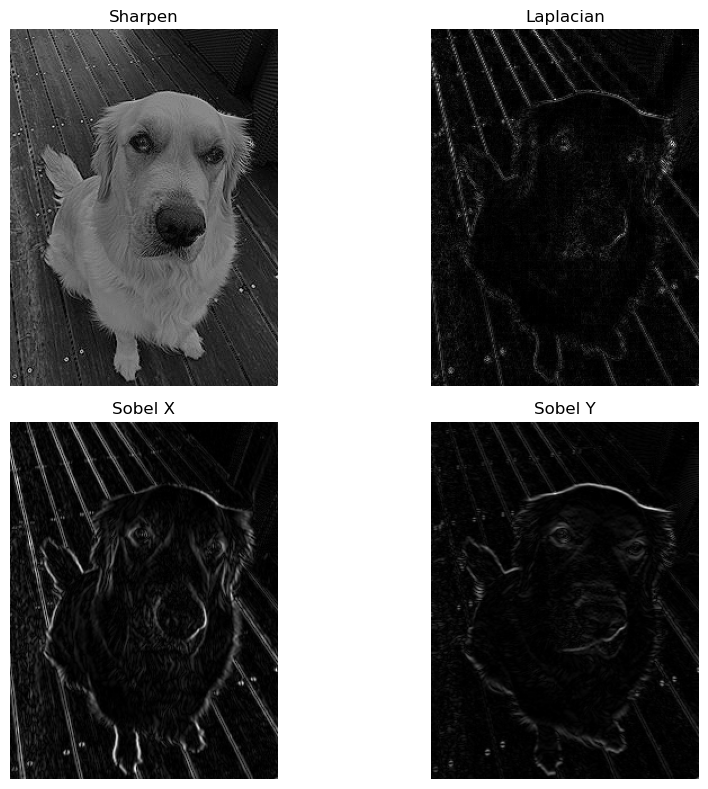

In [2]:
import numpy as np
from torchvision.io import read_image, ImageReadMode
import matplotlib.pyplot as plt

A = np.reshape(np.arange(0,25),(5,5))
K = np.array([1., -1., 2., .5]).reshape((2,2))

print(A)
print(K)

print((A[0:2,0:2]*K).sum())

# Des exemples de filtres de convolution utilisés en image
# (les plus courageux pourront les utiliser à la main sur des images)
# construct a sharpening filter
sharpen = np.array((
	[0, -1, 0],
	[-1, 5, -1],
	[0, -1, 0]), dtype="int")

# construct the Laplacian kernel used to detect edge-like
# regions of an image
laplacian = np.array((
	[0, 1, 0],
	[1, -4, 1],
	[0, 1, 0]), dtype="int")

# construct the Sobel x-axis kernel
sobelX = np.array((
	[-1, 0, 1],
	[-2, 0, 2],
	[-1, 0, 1]), dtype="int")

# construct the Sobel y-axis kernel
sobelY = np.array((
	[-1, -2, -1],
	[0, 0, 0],
	[1, 2, 1]), dtype="int")

def myconvolve2D(A, K):
    decalx = int(K.shape[0] / 2)
    decaly = int(K.shape[1] / 2)

    res = np.zeros((A.shape[0] - 2*decalx, A.shape[1] - 2*decaly))

    for i in range(decalx, A.shape[0] - decalx):
        for j in range(decaly, A.shape[1] - decaly):
            
            window = A[i-decalx:i+decalx+1, j-decaly:j+decaly+1]
            
            res[i-decalx, j-decaly] = np.sum(window * K)

    return res
    
filters = {
    "Sharpen": sharpen,
    "Laplacian": laplacian,
    "Sobel X": sobelX,
    "Sobel Y": sobelY
}

x = read_image("chien.jpg", mode=ImageReadMode.GRAY)
x = x.numpy()

img = x[0,:,:] / 255.

results = {}

for name, kernel in filters.items():
    res = myconvolve2D(img, kernel)
    results[name] = res

plt.figure(figsize=(10, 8))

for i, (name, res) in enumerate(results.items()):
    plt.subplot(2, 2, i+1)
    plt.title(name)
    plt.imshow(np.abs(res), cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

# TD 07 / 1 -- Le classique MNIST

Dans ce TD nous allons mettre en oeuvre l'apprentissage sur les filtres de convolution. Nous le ferons sur la base d'exemple très connue (et très utilisée) MNIST. L'avantage est que cette base est directement disponible dans la distribution de Torch.



In [3]:
''' First part of the work: Read and explore the data
'''
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (7,7) # Make the figures a bit bigger

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms

# Allows to use the GPU if available
if torch.cuda.is_available():
  device = torch.device('cuda')
elif torch.backends.mps.is_available():
  device = torch.device('mps')
else:
  device = torch.device('cpu')


batch_size = 128
num_classes = 10
epochs = 12

# input image dimensions
img_rows, img_cols = 28, 28

trainset = datasets.MNIST(root='./data/', train=True, download=True)
testset = datasets.MNIST(root='./data/', train=False, download=True)
# sets are in the form of set of couple (x,y). The Image x is a PIL.Image.Image object
train_x, train_y = zip(*trainset)
print(len(train_x), "examples loaded for training")

test_x, test_y = zip(*testset)

# Change the images and y into tensors
piltotensor = transforms.ToTensor()

train_x = torch.stack([piltotensor(x) for x in train_x])
train_y = torch.LongTensor(train_y)

test_x = torch.stack([piltotensor(x) for x in test_x])
test_y = torch.LongTensor(test_y)

print("Tensor shapes for train_x and test_x:")
print(train_x.shape, test_x.shape)
print("Tensor shapes for train_y and test_y:")
print(train_y.shape, test_y.shape)


60000 examples loaded for training
Tensor shapes for train_x and test_x:
torch.Size([60000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])
Tensor shapes for train_y and test_y:
torch.Size([60000]) torch.Size([10000])


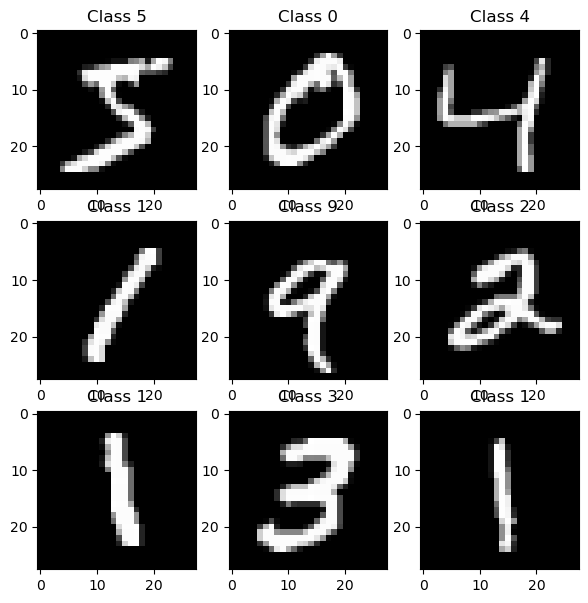

In [4]:
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(train_x[i][0,:,:], cmap='gray', interpolation='none')
    # trainset[i][0,:,:] permet de récupérer l'image i sans la première dimension
    plt.title("Class {}".format(train_y[i]))

plt.show()


## Exploration des données

- Dans un premier temps, vérifiez combien d'éléments sont dans chaque classe
- Vérifiez que les valeurs en entrée pour exprimer les pixels soient entre 0 et 1

### Préparation du *hot-encoding* en sortie

Il s'agit de notre premier réseau neuronal ayant des catégories en sortie. Nous ne devons pas prédire un nombre entre 0 et 9 mais un vecteur de probabilités `Y[0..9]` tel que `Y[i] = p` signifie que le chiffre est `i` avec la probabilité `p`



In [5]:
for i in range(10):
    print(i, ":", np.count_nonzero(np.where(train_y[:] == i)))

print(train_x[0][0])
# on peut observer que, dans les benchs torch, les images sont bien composées de valeurs entre 0 et 1
# (parfois on trouve MNIST avec un taux d'intensité de blanc entre 0 et 255)

0 : 5923
1 : 6742
2 : 5958
3 : 6131
4 : 5842
5 : 5420
6 : 5918
7 : 6265
8 : 5851
9 : 5949
tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.000

In [16]:
def train(model, device, train_loader,  optimizer, epoch):
    model.train()
    total_loss = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target, reduction="mean") # Read the documentation.
        total_loss += loss.item() * len(data) # We average the loss
        loss.backward()
        optimizer.step()
    total_loss /= len(train_loader.dataset)
    return {"train_loss": total_loss}

def test(model, device, test_loader):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_idx, (data, target) in enumerate(test_loader):
            data, target = data.to(device), target.to(device)
            output = model(data)
            loss = F.nll_loss(output, target, reduction="sum")
            total_loss += loss.item()
            predictions = output.argmax(dim=1, keepdim=True)
            correct += predictions.eq(target.view_as(predictions)).sum().item()
            total += len(predictions)
    total_loss /= len(test_loader.dataset)
    return {
        "test_loss": total_loss,
        "correct_rate": f"{correct} / {total}"
    }
trainloader = torch.utils.data.DataLoader(list(zip(train_x, train_y)), batch_size=batch_size, shuffle=True, num_workers=1)

testloader = torch.utils.data.DataLoader(list(zip(test_x, test_y)), batch_size=batch_size, shuffle=False, num_workers=1)


## 1 - Lisez et comprenez sans convolution

Voici un réseau de neurones uniquement avec des couches Denses (probablement très inefficace). Ajoutez des couches et comptez le nombre de neurones / Cherchez des paramètres permettant d'avoir déjà des performances correctes (d'ailleurs quelles performances doit-on mesurer ?)
- Cherchez à minimiser le nombre de couches et de de neurones par couches pour avoir des résultats ayant quasi la même qualité

*Attention*
- les couches Dense vont peut être vous obliger à mettre vos images en entrée sous forme de vecteur d'abord
- il faut définir le modèle puis faire l'apprentissage.


In [ ]:
class WithoutConv(nn.Module):
  def __init__(self):
    super(WithoutConv, self).__init__()
    self.flatten = nn.Flatten(start_dim=1) # Do not flatten the batch dimension
    self.dense1 = nn.Linear(28*28, 128)
    self.dense2 = nn.Linear(128,64)
    self.dense3 = nn.Linear(64, 10) # 10 classes to predict

  def forward(self, x):
    x = self.flatten(x)
    x = self.dense1(x)
    x = F.relu(x)
    x = self.dense2(x)
    x = F.relu(x)
    x = self.dense3(x)
    out = F.log_softmax(x, dim=1) # In torch, we can either use log_softmax + nll_loss or the CrossEntropy (without the last layer of softmax)
    return out


In [ ]:
model1 = WithoutConv().to(device)
import torch.optim as optim 


optimizer = optim.SGD(model1.parameters(), lr=0.001)
for epoch in range(1, 10):
  train_stats = train(model1, device, trainloader, optimizer, epoch)
  test_stats = test(model1, device, testloader)
  print(train_stats, test_stats)


In [14]:
from torch.nn import Sequential, Conv2d, Tanh, ReLU, Dropout, Linear, MaxPool2d


class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 6, 3),  # 1 × 3 × 3 × 6 + 6(b) = 60
            
            nn.MaxPool2d(2),
            nn.ReLU(),
            
            nn.Conv2d(6, 16, 3), # 6 × 3 × 3 × 16 + 16 = 880
            
            nn.MaxPool2d(2), # 11 / 2 = 5
            nn.ReLU(),
            
            nn.Flatten(),
            
            nn.Linear(16 * 5 * 5, 120), # 400 × 120 + 120 = 48120
            nn.ReLU(),
            
            nn.Linear(120, 84), # 120 × 84 + 84 = 10164
            nn.ReLU(),
            
            nn.Linear(84, 10), # 84 × 10 + 10 = 850
            nn.LogSoftmax(dim=1)
        ) # total = 60060 params mais conv répresente 940
        
    def forward(self, x):
        return self.network(x)

In [ ]:
model2 = LeNet5().to(device)
import torch.optim as optim


optimizer = optim.SGD(model2.parameters(), lr=0.01)
for epoch in range(1, 10):
  train_stats = train(model2, device, trainloader, optimizer, epoch)
  test_stats = test(model2, device, testloader)
  print(f"epoch {epoch} : ")
  print(train_stats, test_stats)


epoch 1 - 
{'train_loss': 2.2989559661865235} {'test_loss': 2.290430153274536, 'correct_rate': '3191 / 10000'}
epoch 2 - 
{'train_loss': 2.2660152779897054} {'test_loss': 2.1962693305969236, 'correct_rate': '4395 / 10000'}
epoch 3 - 
{'train_loss': 1.3635151569684347} {'test_loss': 0.6087552839279174, 'correct_rate': '8136 / 10000'}
epoch 4 - 
{'train_loss': 0.48071848204930623} {'test_loss': 0.3931055485248566, 'correct_rate': '8783 / 10000'}
epoch 5 - 
{'train_loss': 0.3678039216995239} {'test_loss': 0.30208566308021545, 'correct_rate': '9105 / 10000'}
epoch 6 - 
{'train_loss': 0.30627401820023853} {'test_loss': 0.2631152805089951, 'correct_rate': '9185 / 10000'}
epoch 7 - 
{'train_loss': 0.26306801025072735} {'test_loss': 0.23486647193431853, 'correct_rate': '9288 / 10000'}
